# Linear and Logistic Regression

**Dataset:** Infant Birth Weight (`birthwt`, 189 observations), from the `MASS` R dataset collection.

**Objectives:** Fit multiple linear regression and multiple logistic regression models; inspect their coefficients; evaluate their predictions using separate training, validation, and test data.

The dataset records maternal characteristics and infant birth weight. The examples illustrate statistical modeling using historical observations and are not intended for clinical decisions.

Dataset documentation: https://search.r-project.org/CRAN/refmans/MASS/html/birthwt.html

## 1. Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix

## 2. Load the dataset

In [ ]:
url = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/MASS/birthwt.csv"
df = pd.read_csv(url)

# Remove the original row identifier.
df = df.drop(columns=["rownames"])

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (189, 10)


,low,age,lwt,race,smoke,ptl,ht,ui,ftv,bwt
0,0,19,182,2,0,0,0,1,0,2523
1,0,33,155,3,0,0,0,0,3,2551
2,0,20,105,1,1,0,0,0,1,2557
3,0,21,108,1,1,0,0,1,2,2594
4,0,18,107,1,1,0,0,1,0,2600


### Variables

| Column | Description |
|---|---|
| `age` | Mother's age in years |
| `lwt` | Mother's weight in pounds at last menstrual period |
| `race` | Categorical code: 1 = white, 2 = black, 3 = other |
| `smoke` | Smoking during pregnancy (0 = no, 1 = yes) |
| `ptl` | Number of previous premature labors |
| `ht` | History of hypertension (0 = no, 1 = yes) |
| `ui` | Presence of uterine irritability (0 = no, 1 = yes) |
| `ftv` | Number of physician visits during the first trimester |
| `bwt` | Infant birth weight (grams) |
| `low` | 1 if birth weight is below 2,500 g; otherwise 0 |

We have **eight predictors**: `age`, `lwt`, `race`, `smoke`, `ptl`, `ht`, `ui`, and `ftv`. The remaining two columns are possible targets. The numeric codes for `race` indicate categories, not a meaningful numerical scale.

In [ ]:
print("Missing values in each column:")
print(df.isna().sum())

print("Numerical summaries:")
display(df.describe().round(1))

print("Class counts for low:")
print(df["low"].value_counts().sort_index())

Missing values in each column:
low      0
age      0
lwt      0
race     0
smoke    0
ptl      0
ht       0
ui       0
ftv      0
bwt      0
dtype: int64
Numerical summaries:


,low,age,lwt,race,smoke,ptl,ht,ui,ftv,bwt
count,189.0,189.0,189.0,189.0,189.0,189.0,189.0,189.0,189.0,189.0
mean,0.3,23.2,129.8,1.8,0.4,0.2,0.1,0.1,0.8,2944.6
std,0.5,5.3,30.6,0.9,0.5,0.5,0.2,0.4,1.1,729.2
min,0.0,14.0,80.0,1.0,0.0,0.0,0.0,0.0,0.0,709.0
25%,0.0,19.0,110.0,1.0,0.0,0.0,0.0,0.0,0.0,2414.0
50%,0.0,23.0,121.0,1.0,0.0,0.0,0.0,0.0,0.0,2977.0
75%,1.0,26.0,140.0,3.0,1.0,0.0,0.0,0.0,1.0,3487.0
max,1.0,45.0,250.0,3.0,1.0,3.0,1.0,1.0,6.0,4990.0


Class counts for low:
low
0    130
1     59
Name: count, dtype: int64


## 3. Prepare the input columns

The three categories of `race` become two binary indicator columns. Category 1 is the reference category: it is represented by zeros in both new columns.

The resulting models use **nine input columns**, representing all eight original predictors. The models must not receive information derived from their targets:

- For linear regression, `bwt` is the target. Exclude `low` because it is calculated using `bwt`.
- For logistic regression, `low` is the target. Exclude `bwt` because the actual birth weight determines whether `low` equals 0 or 1.

In [ ]:
# Convert the categorical race column into indicator columns.
data = pd.get_dummies(df, columns=["race"], drop_first=True, dtype=int)

features = ["age", "lwt", "smoke", "ptl", "ht", "ui", "ftv", "race_2", "race_3"]

print("Number of input columns:", len(features))
display(data[features].head())

Number of input columns: 9


,age,lwt,smoke,ptl,ht,ui,ftv,race_2,race_3
0,19,182,0,0,0,1,0,1,0
1,33,155,0,0,0,0,3,0,1
2,20,105,1,0,0,0,1,0,0
3,21,108,1,0,0,1,2,0,0
4,18,107,1,0,0,1,0,0,0


## Part A. Multiple Linear Regression

The target is the numerical birth weight `bwt`.

For nine features, the hypothesis is

$$
\hat{y} = h_{\vec\theta}(\vec{x}) = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \cdots + \theta_9 x_9.
$$

The model estimates one intercept and nine feature coefficients.

### 4. Select input and target

In [ ]:
X_linear = data[features]
y_linear = data["bwt"]

print("Input shape:", X_linear.shape)
print("Target shape:", y_linear.shape)
display(X_linear.head())

Input shape: (189, 9)
Target shape: (189,)


,age,lwt,smoke,ptl,ht,ui,ftv,race_2,race_3
0,19,182,0,0,0,1,0,1,0
1,33,155,0,0,0,0,3,0,1
2,20,105,1,0,0,0,1,0,0
3,21,108,1,0,0,1,2,0,0
4,18,107,1,0,0,1,0,0,0


### 5. Examine the target distribution

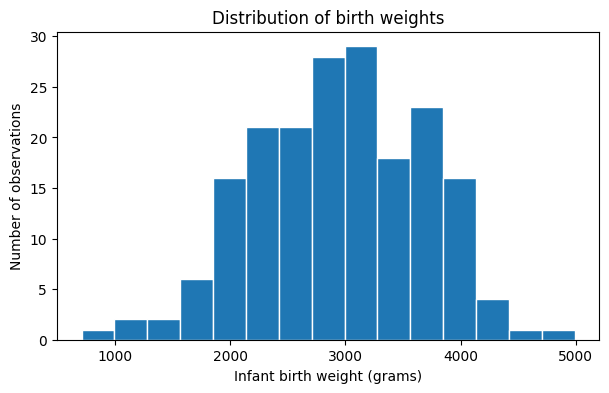

In [ ]:
plt.figure(figsize=(7, 4))
plt.hist(y_linear, bins=15, edgecolor="white")
plt.xlabel("Infant birth weight (grams)")
plt.ylabel("Number of observations")
plt.title("Distribution of birth weights")
plt.show()

### 6. Split the observations

Use approximately **60% training, 20% validation, and 20% testing**. The parameters are estimated from the training set. The validation set measures performance before the final test evaluation.

In [ ]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_linear, y_linear, test_size=0.20, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42
)

print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Test observations:", len(X_test))

Training observations: 113
Validation observations: 38
Test observations: 38


### 7. Fit the linear regression model

In [ ]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

print(f"Intercept (theta_0): {linear_model.intercept_:.2f}")

linear_coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": linear_model.coef_
})
display(linear_coefficients.round(3))

Intercept (theta_0): 2696.99


,Feature,Coefficient
0,age,17.217
1,lwt,3.753
2,smoke,-485.217
3,ptl,118.650
4,ht,-517.579
5,ui,-735.180
6,ftv,-105.900
7,race_2,-511.878
8,race_3,-427.198


The coefficient for an input column represents its contribution to the prediction when the other input columns are held fixed. The coefficients have different units because the inputs have different units. Their numerical magnitudes should not be directly compared to rank importance.

### 8. Validate the linear regression model

In [ ]:
linear_val_predictions = linear_model.predict(X_val)

print(f"Validation MAE: {mean_absolute_error(y_val, linear_val_predictions):.2f} g")
print(f"Validation RMSE: {np.sqrt(mean_squared_error(y_val, linear_val_predictions)):.2f} g")
print(f"Validation R²: {r2_score(y_val, linear_val_predictions):.3f}")

linear_val_table = pd.DataFrame({
    "Actual birth weight": y_val,
    "Predicted birth weight": linear_val_predictions
})
display(linear_val_table.head(10).round(1))

Validation MAE: 605.18 g
Validation RMSE: 746.79 g
Validation R²: -0.289


,Actual birth weight,Predicted birth weight
47,3090,3092.3
38,3005,3340.5
33,2977,3603.2
73,3374,2880.9
188,2495,2225.9
109,3860,2674.9
144,1928,2987.5
25,2877,3805.8
70,3317,3248.2
148,1970,3017.9


### 9. Plot actual and predicted values

With several predictors, the regression model cannot be represented by one fitted line on a two-dimensional scatter plot. Instead, plot actual outcomes against predicted outcomes. Points close to the diagonal correspond to smaller prediction errors.

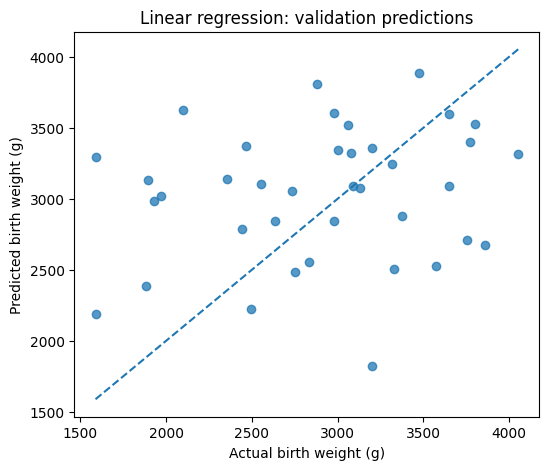

In [ ]:
plt.figure(figsize=(6, 5))
plt.scatter(y_val, linear_val_predictions, alpha=0.75)

low_value = min(y_val.min(), linear_val_predictions.min())
high_value = max(y_val.max(), linear_val_predictions.max())
plt.plot([low_value, high_value], [low_value, high_value], linestyle="--")

plt.xlabel("Actual birth weight (g)")
plt.ylabel("Predicted birth weight (g)")
plt.title("Linear regression: validation predictions")
plt.show()

### 10. Evaluate on the test set

In [ ]:
linear_test_predictions = linear_model.predict(X_test)

print(f"Test MAE: {mean_absolute_error(y_test, linear_test_predictions):.2f} g")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, linear_test_predictions)):.2f} g")
print(f"Test R²: {r2_score(y_test, linear_test_predictions):.3f}")

Test MAE: 570.10 g
Test RMSE: 712.41 g
Test R²: 0.002


### 11. Predict a new observation

In [ ]:
# One hypothetical observation, using every input column.
new_case = pd.DataFrame([{
    "age": 26,
    "lwt": 130,
    "smoke": 0,
    "ptl": 0,
    "ht": 0,
    "ui": 0,
    "ftv": 1,
    "race_2": 0,
    "race_3": 1
}], columns=features)

display(new_case)

new_birth_weight = linear_model.predict(new_case)[0]
print(f"Predicted birth weight: {new_birth_weight:.1f} grams")

,age,lwt,smoke,ptl,ht,ui,ftv,race_2,race_3
0,26,130,0,0,0,0,1,0,1


Predicted birth weight: 3099.4 grams


## Part B. Multiple Logistic Regression

Now the target is `low`, a binary outcome:

- $y=1$: birth weight below 2,500 grams.
- $y=0$: birth weight at least 2,500 grams.

The logistic regression model first calculates a linear score

$$
z = \theta_0 + \theta_1x_1 + \cdots + \theta_9x_9,
$$

then converts it into a probability using the sigmoid function:

$$
P(y=1\mid\vec{x})=\frac{1}{1+e^{-z}}.
$$

### 12. Select input and target

In [ ]:
X_logistic = data[features]
y_logistic = data["low"]

print("Input shape:", X_logistic.shape)
print("Target counts:")
print(y_logistic.value_counts().sort_index())

Input shape: (189, 9)
Target counts:
low
0    130
1     59
Name: count, dtype: int64


### 13. Examine the class distribution

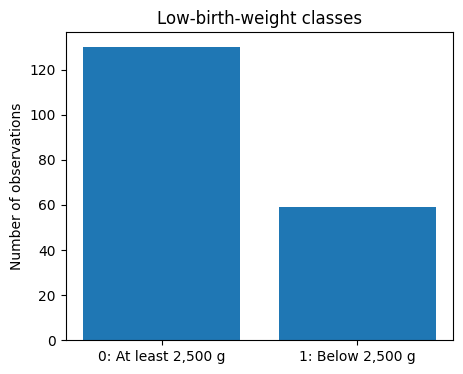

In [ ]:
class_counts = y_logistic.value_counts().sort_index()

plt.figure(figsize=(5, 4))
plt.bar(["0: At least 2,500 g", "1: Below 2,500 g"], class_counts.values)
plt.ylabel("Number of observations")
plt.title("Low-birth-weight classes")
plt.show()

### 14. Split into training, validation, and test sets

Use a stratified split to preserve approximately the same proportion of class 0 and class 1 in each set.

In [ ]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_logistic, y_logistic, test_size=0.20, random_state=42, stratify=y_logistic
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42,
    stratify=y_train_val
)

print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Test observations:", len(X_test))
print("Class proportions in training set:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

Training observations: 113
Validation observations: 38
Test observations: 38
Class proportions in training set:
low
0    0.69
1    0.31
Name: proportion, dtype: float64


### 15. Fit the logistic regression model

In [ ]:
logistic_model = LogisticRegression(solver="liblinear", max_iter=5000)
logistic_model.fit(X_train, y_train)

print(f"Intercept (theta_0): {logistic_model.intercept_[0]:.4f}")

logistic_coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": logistic_model.coef_[0]
})
display(logistic_coefficients.round(4))

Intercept (theta_0): 0.0361


,Feature,Coefficient
0,age,-0.0048
1,lwt,-0.0111
2,smoke,0.4931
3,ptl,1.0194
4,ht,0.2614
5,ui,0.5068
6,ftv,-0.0889
7,race_2,1.2465
8,race_3,0.2084


The parameters determine the linear score $z$. The probability is obtained by applying the sigmoid function. A coefficient indicates how its corresponding predictor changes the score when the remaining predictors are fixed.

### 16. Validate probabilities and predicted classes

In [ ]:
logistic_val_probabilities = logistic_model.predict_proba(X_val)[:, 1]
logistic_val_classes = logistic_model.predict(X_val)

print(f"Validation accuracy: {accuracy_score(y_val, logistic_val_classes):.3f}")
print(f"Validation log loss: {log_loss(y_val, logistic_val_probabilities):.3f}")

logistic_val_table = pd.DataFrame({
    "Actual class": y_val,
    "Probability of class 1": logistic_val_probabilities,
    "Predicted class": logistic_val_classes
})
display(logistic_val_table.head(10).round(3))

Validation accuracy: 0.553
Validation log loss: 0.766


,Actual class,Probability of class 1,Predicted class
26,0,0.289,0
8,0,0.258,0
78,0,0.585,1
73,0,0.492,0
16,0,0.532,1
55,0,0.260,0
152,1,0.427,0
167,1,0.281,0
139,1,0.227,0
162,1,0.258,0


Accuracy is the fraction of correctly classified observations. Log loss additionally evaluates the probabilities assigned to the outcomes that actually occurred. The default classification threshold is 0.5.

### 17. Examine the confusion matrix

In [ ]:
val_matrix = confusion_matrix(y_val, logistic_val_classes, labels=[0, 1])

print("Rows: actual 0, actual 1")
print("Columns: predicted 0, predicted 1")
print(val_matrix)

Rows: actual 0, actual 1
Columns: predicted 0, predicted 1
[[20  6]
 [11  1]]


### 18. Evaluate on the test set

In [ ]:
logistic_test_probabilities = logistic_model.predict_proba(X_test)[:, 1]
logistic_test_classes = logistic_model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, logistic_test_classes):.3f}")
print(f"Test log loss: {log_loss(y_test, logistic_test_probabilities):.3f}")
print("Test confusion matrix:")
print(confusion_matrix(y_test, logistic_test_classes, labels=[0, 1]))

Test accuracy: 0.789
Test log loss: 0.489
Test confusion matrix:
[[26  0]
 [ 8  4]]


### 19. Predict a new observation

In [ ]:
# Reuse the hypothetical observation from Part A.
new_probability = logistic_model.predict_proba(new_case)[0, 1]
new_class = logistic_model.predict(new_case)[0]

print(f"Predicted probability of low birth weight: {new_probability:.3f}")
print(f"Predicted class: {new_class}")

Predicted probability of low birth weight: 0.197
Predicted class: 0


## Questions

1. Identify the eight original predictors and explain why there are nine input columns after encoding.
2. Why must `low` be excluded when predicting `bwt`?
3. Why must `bwt` be excluded when predicting `low`?
4. What do the intercept and coefficients represent in multiple linear regression?
5. Why can the multiple linear regression model not be represented by a single fitted line in the scatter plot?
6. What information does the actual-versus-predicted plot provide?
7. What is the distinction between the predicted probability and predicted class in logistic regression?
8. Why are training, validation, and test sets kept separate?
9. Why is the logistic split stratified?
10. Can a larger absolute coefficient alone establish that a feature is more important? Explain.